# Predicción de horas hombre — Entradas a almacén (handhelds)

**Objetivo de negocio:** estimar las **horas hombre** de trabajo de almacén que se necesitarán, a
partir del histórico de entradas (API SGA), para planear personal y turnos.

Este notebook **reutiliza** la carga de datos de `fuente_unica_entradas.ipynb` (§6, API SGA con hora
real) y **replica la estructura y las gráficas** de `Timeseries.ipynb` (SARIMA + Prophet, en *dark
mode*), adaptadas de una serie **mensual** a una serie **horaria**.

> **Variable objetivo — "horas hombre de presencia":** número de usuarios distintos activos en cada
> hora reloj. Una persona presente y trabajando en una hora ⇒ 1 hora-hombre. Es un **proxy de
> presencia** (no horas de nómina), pero es exactamente lo que se programa contra turnos.

# Bibliotecas y funciones

In [7]:
!pip install prophet

In [8]:
import os
os.environ.setdefault("OMP_NUM_THREADS", "1")  # evita sobre-suscripción de BLAS en la rejilla SARIMAX
import itertools

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import seaborn as sns

import statsmodels
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.stattools import adfuller
from statsmodels.tsa.statespace.sarimax import SARIMAX
from prophet import Prophet

from sklearn.metrics import mean_squared_error, mean_absolute_error
from joblib import Parallel, delayed

from lisa_client import LisaClient, LisaAPIError

In [9]:
#@title Dark Mode
plt.style.use("dark_background")
plt.rcParams.update({
    "figure.facecolor": "#111111", "axes.facecolor": "#111111", "savefig.facecolor": "#111111",
    "axes.edgecolor": "white", "axes.labelcolor": "white", "text.color": "white",
    "xtick.color": "white", "ytick.color": "white",
    "grid.color": "lightgray", "grid.linestyle": "--", "grid.linewidth": 0.5,
    "lines.linewidth": 1.5, "lines.markersize": 5, "font.size": 10,
    "figure.figsize": (8, 6), "savefig.dpi": 150, "savefig.bbox": "tight",
    "legend.edgecolor": "white", "legend.frameon": True, "legend.fancybox": False,
})
sns.set_style("darkgrid", {
    "axes.facecolor": "#111111", "figure.facecolor": "#111111", "grid.color": "#333333",
    "text.color": "white", "axes.labelcolor": "white", "xtick.color": "white", "ytick.color": "white",
})

In [10]:
def _oscurecer(fig):
    """Fuerza modo oscuro en figuras que crean su propia Figure (seasonal_decompose,
    plot_diagnostics, Prophet.plot / plot_components), que no heredan bien los rcParams."""
    fig.patch.set_facecolor("#111111")
    for ax in fig.get_axes():
        ax.set_facecolor("#111111")
        ax.tick_params(colors="white")
        for spine in ax.spines.values():
            spine.set_edgecolor("white")
        ax.xaxis.label.set_color("white"); ax.yaxis.label.set_color("white")
        ax.title.set_color("white")
        # Recolorea artistas negros (p. ej. los puntos de historia de Prophet) para que se vean.
        for ln in ax.get_lines():
            r, g, b, _ = mcolors.to_rgba(ln.get_color())
            if r < 0.2 and g < 0.2 and b < 0.2:
                ln.set_color("#cccccc")
        leg = ax.get_legend()
        if leg is not None:
            for t in leg.get_texts():
                t.set_color("white")
    fig.tight_layout()
    return fig

In [11]:
def p_value_adfuller(data):
        fuller_test = adfuller(data)
        print("P-value: ", fuller_test[1])
        if fuller_test[1] <= 0.05:
            print("Se rechaza la hipótesis nula, los datos son estacionarios")
        else:
            print("No se rechaza la hipóteis nula, los datos no son estacionarios")

## Constantes de adaptación (mensual → horario)

Todo el mapeo de `Timeseries.ipynb` (mensual, `period=12`) a esta serie **horaria** se concentra aquí.

In [12]:
PERIODO        = 24            # estacionalidad diaria (horas) -> ranura estacional de SARIMA
PERIODO_SEMANA = 168           # estacionalidad semanal (horas) -> vía exóg. de Fourier
FREQ           = "h"           # frecuencia horaria (minúscula; "H" está deprecada en pandas)
LAGS           = 48            # 2 días, para ver el peine diario en ACF/PACF
VENTANA_MM     = 24            # media móvil de 24 h
HORAS_LAB      = range(6, 21)  # ventana laboral observada (06–20h)
DIAS_TEST      = 7             # holdout = última semana completa
PERIODOS_FUT   = DIAS_TEST * 24    # 168 h: horizonte de pronóstico (igual SARIMA y Prophet)
K_FOURIER      = 3             # armónicos de la estacionalidad semanal

# Lectura y construcción de la serie de tiempo

## 1. Lectura de la fuente con hora — API SGA (`sga_entradas`)

Reutilizamos el cargador de `fuente_unica_entradas.ipynb` §6. El **API SGA** ya entrega las fechas
**con hora** (`fecha_inicio` / `fecha_fin` traen `HH:MM:SS` reales), así que es la **fuente única**
también para el análisis horario. El parámetro `p_fecha_gen` actúa como **cota inferior**: con una
fecha temprana, una sola llamada trae toda la historia disponible. Usamos `fecha_inicio` como el
instante en que el empleado arrancó la tarea en la handheld.

In [13]:
# --- Fuente CON hora: API SGA (fecha_inicio/fecha_fin ya traen HH:MM:SS reales) ---
# p_fecha_gen actúa como COTA INFERIOR: una fecha temprana trae toda la historia disponible.
try:
    from dotenv import load_dotenv
    load_dotenv()
except ImportError:
    pass

assert os.getenv("LISA_TOKEN"), "Falta LISA_TOKEN (.env o variable de entorno) para consultar el API SGA."

FECHA_DESDE = "01/01/2025"   # dd/mm/aaaa — cota inferior amplia; el API devuelve todo lo posterior
ALMACEN     = "5460D"        # "" = todos los almacenes

client = LisaClient()
try:
    respuesta = client.entradas_almacen(fecha_gen=FECHA_DESDE, almacen=ALMACEN, regs=-1)
except LisaAPIError as e:
    raise SystemExit(f"Error en la API LISA: {e}")

registros = respuesta.get("registros", {})
reg = registros.get("reg") or []
if isinstance(reg, dict):   # un solo registro -> lista de uno
    reg = [reg]
ent = pd.json_normalize(reg)

# Fechas del endpoint a datetime (format="mixed" preserva la hora que ahora sí envía el API).
for col in ["fecha_gen", "fecha_inicio", "fecha_fin"]:
    ent[col] = pd.to_datetime(ent[col], format="mixed", dayfirst=True, errors="coerce")
print(f"API sga_entradas: {len(ent):,} filas | "
      f"fecha_inicio {ent['fecha_inicio'].min():%d-%b-%Y %H:%M} → {ent['fecha_inicio'].max():%d-%b-%Y %H:%M}")

# --- Variables temporales sobre fecha_inicio (= arranque de la tarea en la handheld) ---
ent = ent[ent["fecha_inicio"].notna()].copy()

# Usuarios de negocio: excluimos cuentas de sistema y nulos (configurable).
SYS_USERS = {"ADMIN", "", None}
ent = ent[ent["usuario"].notna() & ~ent["usuario"].isin(SYS_USERS)].copy()

ent["hora"] = ent["fecha_inicio"].dt.hour
ent["fecha"] = ent["fecha_inicio"].dt.normalize()  # día (sin hora)
DOW_ES = ["Lun", "Mar", "Mié", "Jue", "Vie", "Sáb", "Dom"]
ent["dia_sem"] = pd.Categorical(
    ent["fecha_inicio"].dt.dayofweek.map(dict(enumerate(DOW_ES))),
    categories=DOW_ES, ordered=True,
)

# Duración de la tarea (min), acotada (cap 30 min) para no contaminar métricas de tiempo ocupado.
DUR_CAP_MIN = 30
ent["dur_min"] = (ent["fecha_fin"] - ent["fecha_inicio"]).dt.total_seconds() / 60.0
ent.loc[(ent["dur_min"] < 0) | (ent["dur_min"] > DUR_CAP_MIN), "dur_min"] = np.nan

print(f"Tareas: {len(ent):,} | usuarios: {ent['usuario'].nunique()} | handhelds: {ent['maquina'].nunique()}")

12:05:28 [INFO] POST /galileo/lisa/geninf/isp/sga_entradas | body: {'p_fecha_gen': '01/01/2025', 'p_almacen': '5460D'}


API sga_entradas: 3,389 filas | fecha_inicio 02-Jan-2026 15:57 → 22-Jun-2026 12:03
Tareas: 3,389 | usuarios: 26 | handhelds: 18


## Definición de la variable objetivo — horas hombre de presencia (por hora)

Para cada **hora reloj** contamos cuántos **usuarios distintos** estuvieron activos (= horas-hombre
acumuladas en esa hora). Se dejan comentadas dos alternativas intercambiables: **B** tiempo
realmente laborado (`dur_min/60`, diminuto y ruidoso por el cap de 30 min) y **C** volumen de tareas.

In [14]:
# Sello de tiempo a la hora (floor) y conteo de usuarios distintos por hora reloj.
ent["ts"] = ent["fecha_inicio"].dt.floor(FREQ)
hh = ent.groupby("ts")["usuario"].nunique()
hh.name = "HorasHombre"

# --- Alternativas (descomentar para intercambiar la variable objetivo) ---
# B) Tiempo laborado (horas) = suma de duraciones / 60  (diminuto y ruidoso, cap 30 min)
# hh = ent.groupby("ts")["dur_min"].sum().div(60).rename("HorasHombre")
# C) Volumen de tareas por hora (proxy de carga)
# hh = ent.groupby("ts").size().rename("HorasHombre")

print(f"Horas con actividad: {len(hh):,} | "
      f"rango {hh.index.min():%d-%b-%Y %H:%M} → {hh.index.max():%d-%b-%Y %H:%M}")
hh.head()

Horas con actividad: 593 | rango 02-Jan-2026 15:00 → 22-Jun-2026 12:00


ts
2026-01-02 15:00:00    5
2026-01-02 16:00:00    6
2026-01-05 13:00:00    1
2026-01-05 16:00:00    1
2026-01-05 18:00:00    1
Name: HorasHombre, dtype: int64

## Asegurar el orden y la continuidad de la serie de tiempo

La serie debe ser **monótona** y **continua** en su frecuencia. La serie horaria tiene **huecos
reales** (horas sin ninguna entrada: noches, fines de semana, cierres) que rellenamos con **0**
(cero presencia es un valor verdadero, no un dato faltante; usar `ffill` inventaría trabajo fantasma).

In [15]:
hh.index.is_monotonic_increasing

True

In [16]:
# Horas esperadas (rejilla horaria continua) vs. horas presentes -> huecos a rellenar con 0.
obsEsperadas = pd.date_range(start=hh.index.min().floor("D"), end=hh.index.max(), freq=FREQ)
faltantes = obsEsperadas[~obsEsperadas.isin(hh.index)]
print(f"Horas esperadas: {len(obsEsperadas):,} | con actividad: {len(hh):,} | "
      f"huecos (0 h-hombre): {len(faltantes):,}")
faltantes[:10]

Horas esperadas: 4,117 | con actividad: 593 | huecos (0 h-hombre): 3,524


DatetimeIndex(['2026-01-02 00:00:00', '2026-01-02 01:00:00',
               '2026-01-02 02:00:00', '2026-01-02 03:00:00',
               '2026-01-02 04:00:00', '2026-01-02 05:00:00',
               '2026-01-02 06:00:00', '2026-01-02 07:00:00',
               '2026-01-02 08:00:00', '2026-01-02 09:00:00'],
              dtype='datetime64[ns]', freq=None)

In [17]:
serie = hh.reindex(obsEsperadas, fill_value=0).astype(float)
datos = serie.to_frame("HorasHombre")
datos.index.freq = FREQ   # frecuencia asignada DESPUÉS del reindex continuo
print(f"Serie continua: {len(datos):,} horas | freq={datos.index.freq} | "
      f"{(datos['HorasHombre'] == 0).mean():.0%} de ceros (noche/fin de semana/cierres)")
datos.head()

Serie continua: 4,117 horas | freq=<Hour> | 86% de ceros (noche/fin de semana/cierres)


,HorasHombre
2026-01-02 00:00:00,0.0
2026-01-02 01:00:00,0.0
2026-01-02 02:00:00,0.0
2026-01-02 03:00:00,0.0
2026-01-02 04:00:00,0.0


In [18]:
end_ts = datos.index.max()
split_ts = end_ts - pd.Timedelta(hours=PERIODOS_FUT)   # holdout = última semana (168 h)
print("Fin de la serie :", end_ts)
print("Corte train/test:", split_ts)

Fin de la serie : 2026-06-22 12:00:00
Corte train/test: 2026-06-15 12:00:00


# División de la serie en entrenamiento y prueba

Reservamos la **última semana completa** (168 h) como prueba — análogo horario de reservar un ciclo
estacional en `Timeseries.ipynb`. Mismo corte y horizonte para SARIMA y Prophet.

In [19]:
train = datos.loc[:split_ts, "HorasHombre"].copy()
test  = datos.loc[split_ts + pd.Timedelta(hours=1):, "HorasHombre"].copy()
train.index.freq = FREQ
test.index.freq = FREQ
assert len(test) == PERIODOS_FUT, f"test debe tener {PERIODOS_FUT} h, tiene {len(test)}"
print(f"train: {len(train):,} h ({train.index.min():%d-%b %H:%M} → {train.index.max():%d-%b %H:%M})")
print(f"test : {len(test):,} h ({test.index.min():%d-%b %H:%M} → {test.index.max():%d-%b %H:%M})")

train: 3,949 h (02-Jan 00:00 → 15-Jun 12:00)
test : 168 h (15-Jun 13:00 → 22-Jun 12:00)


# Exploración y Visualización de la Serie Temporal

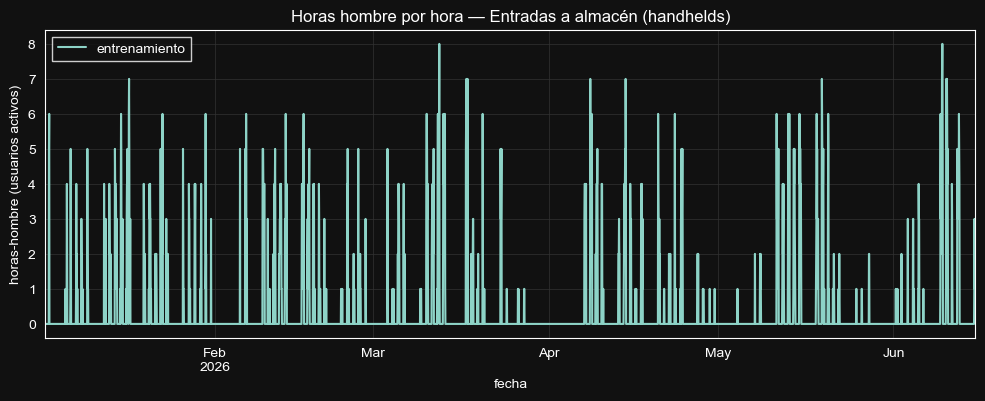

In [20]:
ax = train.plot(figsize=(12, 4), label="entrenamiento",
                title="Horas hombre por hora — Entradas a almacén (handhelds)")
ax.set_xlabel("fecha"); ax.set_ylabel("horas-hombre (usuarios activos)")
plt.legend(); plt.show()

**¿Es la serie estacionaria?** La media móvil de 24 h ayuda a ver la tendencia bajo el fuerte
ciclo diario.

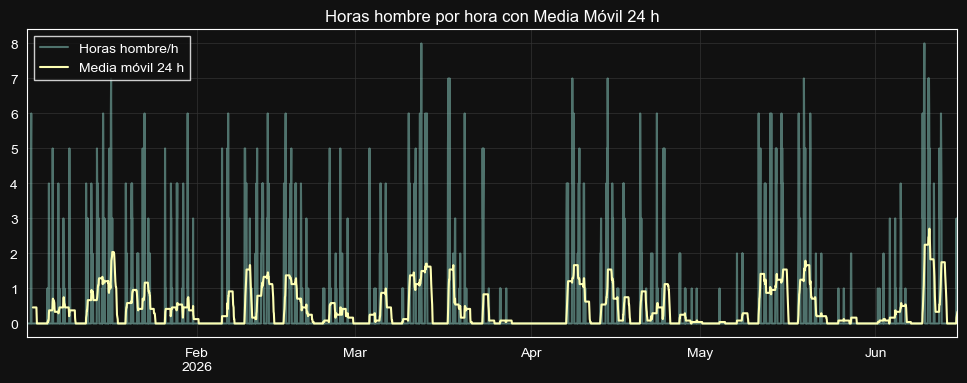

In [21]:
ax = train.plot(figsize=(12, 4), label="Horas hombre/h", alpha=0.5)
train.rolling(VENTANA_MM).mean().plot(ax=ax, label=f"Media móvil {VENTANA_MM} h")
plt.title(f"Horas hombre por hora con Media Móvil {VENTANA_MM} h")
plt.legend(); plt.show()

`seasonal_decompose` separa la serie en **tendencia**, **temporalidad** (perfil diario de 24 h)
y **residuos**. Usamos `period=24` (estacionalidad diaria) y modelo **aditivo** (los ceros nocturnos
hacen inapropiado el multiplicativo).

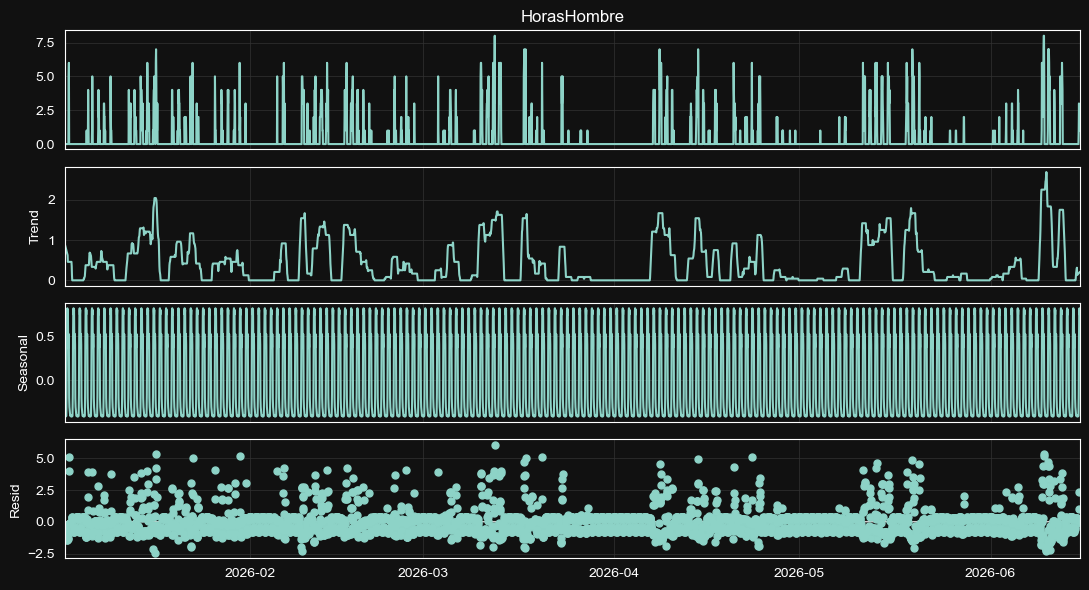

In [22]:
decomposition = seasonal_decompose(train, model="additive", period=PERIODO, extrapolate_trend="freq")
fig = decomposition.plot(); fig.set_size_inches(11, 6)
_oscurecer(fig); plt.show()

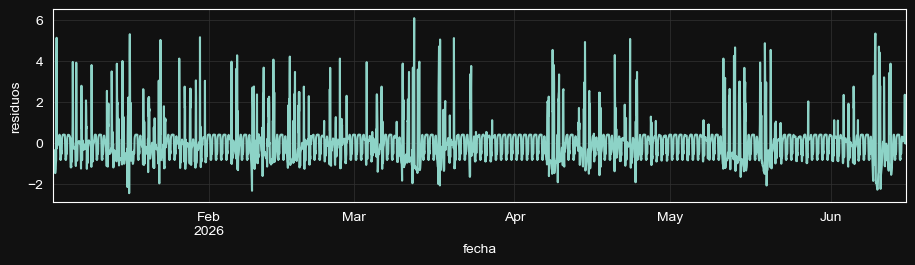

In [23]:
residuals = decomposition.resid
residuals.plot(figsize=(11, 2.5))
plt.ylabel("residuos"); plt.xlabel("fecha"); plt.show()

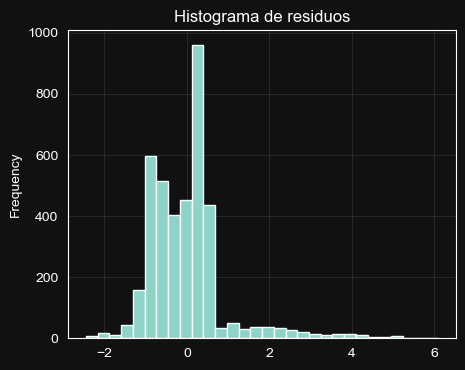

In [24]:
_ = residuals.dropna().plot.hist(figsize=(5, 4), bins=30)
plt.title("Histograma de residuos"); plt.show()

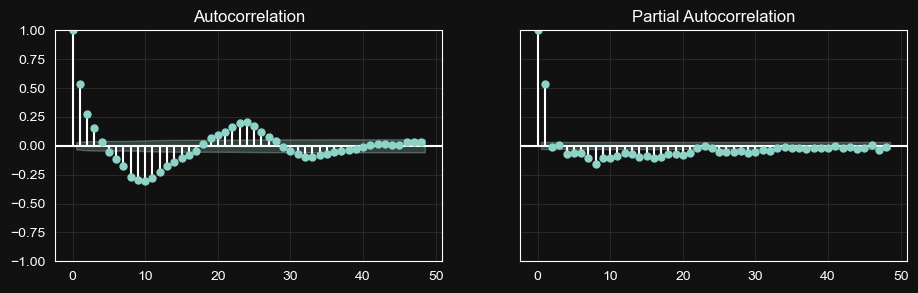

In [25]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3), sharey=True)
plot_acf(residuals.dropna(),  lags=LAGS, ax=axes[0])
plot_pacf(residuals.dropna(), lags=LAGS, ax=axes[1])
plt.show()

Las correlaciones significativas (sobre todo el **peine en 24 y 48 h**) indican que modelar la
serie con un **SARIMA estacional (s=24)** es buena idea. La estacionalidad **semanal (168 h)** se
añade como **exógenas de Fourier**: una sola ranura estacional no alcanza para 24 y 168 a la vez.

# Construcción del modelo SARIMA

## Estacionariedad de la serie (parámetro d)

**Test Dickey-Fuller** — H0: la serie *no* es estacionaria (si *p* es pequeña, se rechaza H0).

In [26]:
p_value_adfuller(train)

P-value:  2.2196441187449297e-12
Se rechaza la hipótesis nula, los datos son estacionarios


La serie horaria ya es **estacionaria** (el ciclo diurno la hace revertir a la media), así que
**d = 0**. Mostramos igualmente la 1ª diferencia de forma ilustrativa.

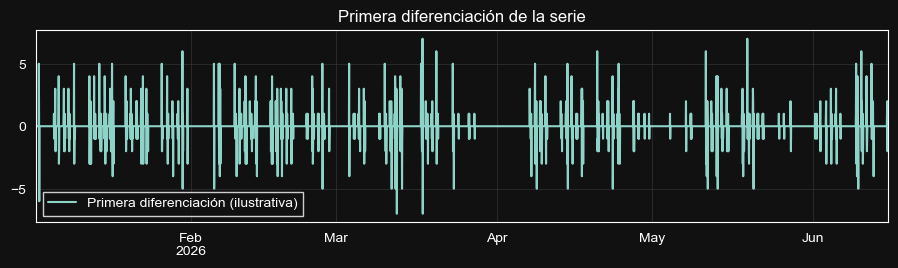

In [27]:
train_1diff = train - train.shift(1)
train_1diff.plot(figsize=(11, 2.5), label="Primera diferenciación (ilustrativa)")
plt.title("Primera diferenciación de la serie"); plt.legend(); plt.show()

In [28]:
p_value_adfuller(train_1diff.dropna())

P-value:  0.0
Se rechaza la hipótesis nula, los datos son estacionarios


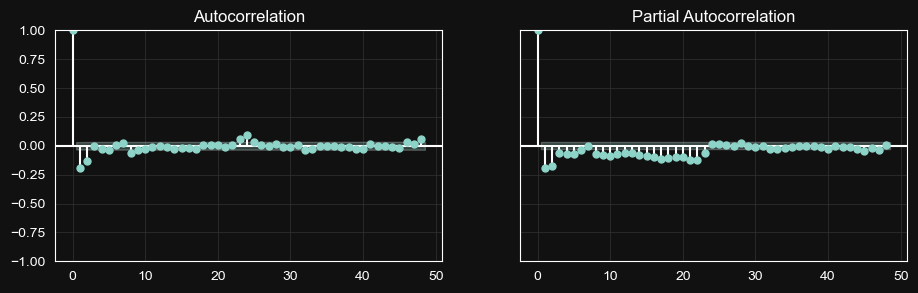

In [29]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3), sharey=True)
plot_acf(train_1diff.dropna(),  lags=LAGS, ax=axes[0])
plot_pacf(train_1diff.dropna(), lags=LAGS, ax=axes[1])
plt.show()

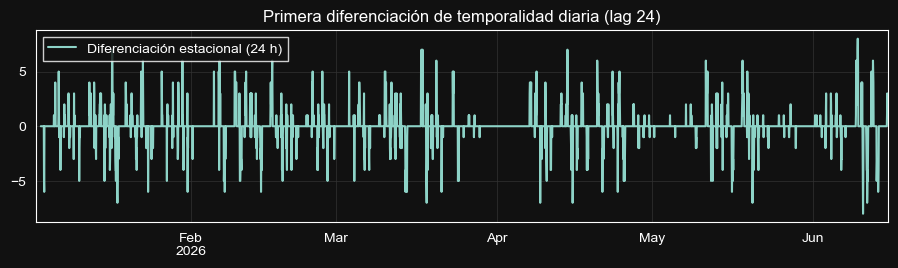

In [30]:
train_24diff = train - train.shift(PERIODO)
train_24diff.plot(figsize=(11, 2.5), label="Diferenciación estacional (24 h)")
plt.title("Primera diferenciación de temporalidad diaria (lag 24)"); plt.legend(); plt.show()

In [31]:
p_value_adfuller(train_24diff.dropna())

P-value:  4.144136384896637e-24
Se rechaza la hipótesis nula, los datos son estacionarios


Por tanto **d = 0** y **D = 1** (una diferencia estacional en el lag 24). `D = 2` nunca.

## Estacionalidad semanal vía exógenas de Fourier (período 168)

SARIMA solo tiene **una** ranura estacional (la usamos para 24 h). El ciclo **semanal** (caída de fin
de semana) se inyecta como **términos de Fourier** (seno/coseno de período 168). La base es
determinista en el tiempo: se construye sobre un índice **continuo** que cubre train + futuro y luego
se **rebana** (no reiniciar `t` para el futuro, o la fase del fin de semana saldría mal).

In [32]:
def fourier_terms(index, period, K):
    """Matriz de términos de Fourier (seno/coseno) para una estacionalidad de longitud `period`."""
    t = np.arange(len(index))
    out = {}
    for k in range(1, K + 1):
        out[f"s{period}_sin{k}"] = np.sin(2 * np.pi * k * t / period)
        out[f"s{period}_cos{k}"] = np.cos(2 * np.pi * k * t / period)
    return pd.DataFrame(out, index=index)

exog = fourier_terms(datos.index, PERIODO_SEMANA, K_FOURIER)   # sobre TODA la serie (continua)
exog_train = exog.loc[:split_ts]
exog_fut   = exog.loc[split_ts + pd.Timedelta(hours=1):]
print(f"exóg. Fourier semanal: {exog.shape[1]} columnas | "
      f"train {exog_train.shape[0]} | futuro {exog_fut.shape[0]}")
exog.head()

exóg. Fourier semanal: 6 columnas | train 3949 | futuro 168


,s168_sin1,s168_cos1,s168_sin2,s168_cos2,s168_sin3,s168_cos3
2026-01-02 00:00:00,0.000000,1.000000,0.000000,1.000000,0.000000,1.000000
2026-01-02 01:00:00,0.037391,0.999301,0.074730,0.997204,0.111964,0.993712
2026-01-02 02:00:00,0.074730,0.997204,0.149042,0.988831,0.222521,0.974928
2026-01-02 03:00:00,0.111964,0.993712,0.222521,0.974928,0.330279,0.943883
2026-01-02 04:00:00,0.149042,0.988831,0.294755,0.955573,0.433884,0.900969


## Orden del modelo SARIMA (p, d, q) × (P, D, Q, 24)

Buscamos el orden con una rejilla **acotada** (p, q, P, Q ∈ {0, 1}; d = 0, D = 1, s = 24 ⇒ 16
ajustes), rankeada por AIC. Con ~4 000 puntos y s = 24 una rejilla mayor sería de minutos a horas;
mantenemos el espacio pequeño y cada ajuste protegido con `try/except`.

In [33]:
p = q = range(0, 2)
pdq = list(itertools.product(p, [0], q))                              # d = 0 fijo
P = Q = range(0, 2)
PDQs = [(x[0], 1, x[1], PERIODO) for x in itertools.product(P, Q)]    # D = 1, s = 24
print("No estacional (p,d,q):", pdq)
print("Estacional (P,D,Q,s) :", PDQs)

No estacional (p,d,q): [(0, 0, 0), (0, 0, 1), (1, 0, 0), (1, 0, 1)]
Estacional (P,D,Q,s) : [(0, 1, 0, 24), (0, 1, 1, 24), (1, 1, 0, 24), (1, 1, 1, 24)]


In [34]:
%%time
def fit_sarimax_model(parametros, parametros_s):
    try:
        modelo = SARIMAX(train, order=parametros, seasonal_order=parametros_s,
                         enforce_stationarity=False, enforce_invertibility=False)
        res = modelo.fit(disp=False, maxiter=50)
        return (parametros, parametros_s), res.aic
    except Exception:
        return (parametros, parametros_s), np.inf

resultados_grid = Parallel(n_jobs=4)(
    delayed(fit_sarimax_model)(o, s) for o in pdq for s in PDQs
)
aic_modelos = dict(resultados_grid)

CPU times: total: 281 ms
Wall time: 1min 14s


In [35]:
mejor = min(aic_modelos, key=aic_modelos.get)
print("Mejor orden por AIC (rejilla sin exóg.):", mejor, "| AIC =", round(aic_modelos[mejor], 1))
aic_modelos

Mejor orden por AIC (rejilla sin exóg.): ((1, 0, 1), (1, 1, 1, 24)) | AIC = 9552.4


{((0, 0, 0), (0, 1, 0, 24)): np.float64(13418.553505143655),
 ((0, 0, 0), (0, 1, 1, 24)): np.float64(11814.602820537077),
 ((0, 0, 0), (1, 1, 0, 24)): np.float64(12781.239765768687),
 ((0, 0, 0), (1, 1, 1, 24)): np.float64(11590.635346335795),
 ((0, 0, 1), (0, 1, 0, 24)): np.float64(12269.791369642553),
 ((0, 0, 1), (0, 1, 1, 24)): np.float64(10304.913317311617),
 ((0, 0, 1), (1, 1, 0, 24)): np.float64(11459.207111217162),
 ((0, 0, 1), (1, 1, 1, 24)): np.float64(10206.603710566666),
 ((1, 0, 0), (0, 1, 0, 24)): np.float64(11882.991156866221),
 ((1, 0, 0), (0, 1, 1, 24)): np.float64(9617.288940392767),
 ((1, 0, 0), (1, 1, 0, 24)): np.float64(10919.604179273068),
 ((1, 0, 0), (1, 1, 1, 24)): np.float64(9580.600389754349),
 ((1, 0, 1), (0, 1, 0, 24)): np.float64(11859.677866424096),
 ((1, 0, 1), (0, 1, 1, 24)): np.float64(9592.474077181645),
 ((1, 0, 1), (1, 1, 0, 24)): np.float64(10894.606592507527),
 ((1, 0, 1), (1, 1, 1, 24)): np.float64(9552.388218942828)}

La rejilla orienta el orden, pero el **forecaster final** usa un orden **parsimonioso y
robusto** —`(1,0,1)(0,1,1,24)`, estilo *airline*— **con** las exógenas de Fourier semanal.
Hard-codear el orden rico del tutorial original `(1,1,2)(2,1,2,·)` sobre solo ~21 ciclos semanales
sería sobre-parametrizar.

In [36]:
modelo = SARIMAX(train, exog=exog_train,
                 order=(1, 0, 1), seasonal_order=(0, 1, 1, PERIODO),
                 enforce_stationarity=False, enforce_invertibility=False)
resultados = modelo.fit(disp=False, maxiter=50)
print(resultados.summary().tables[1])

                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
s168_sin1     -0.2870      0.085     -3.383      0.001      -0.453      -0.121
s168_cos1      0.0832      0.065      1.280      0.201      -0.044       0.211
s168_sin2      0.1489      0.077      1.937      0.053      -0.002       0.300
s168_cos2      0.1477      0.069      2.126      0.033       0.012       0.284
s168_sin3      0.0603      0.072      0.838      0.402      -0.081       0.201
s168_cos3      0.0079      0.066      0.119      0.905      -0.122       0.138
ar.L1          0.7034      0.011     64.302      0.000       0.682       0.725
ma.L1         -0.1157      0.014     -8.523      0.000      -0.142      -0.089
ma.S.L24      -1.0000    161.354     -0.006      0.995    -317.248     315.248
sigma2         0.6584    106.233      0.006      0.995    -207.554     208.871


# Validación

## Análisis de los residuos del modelo

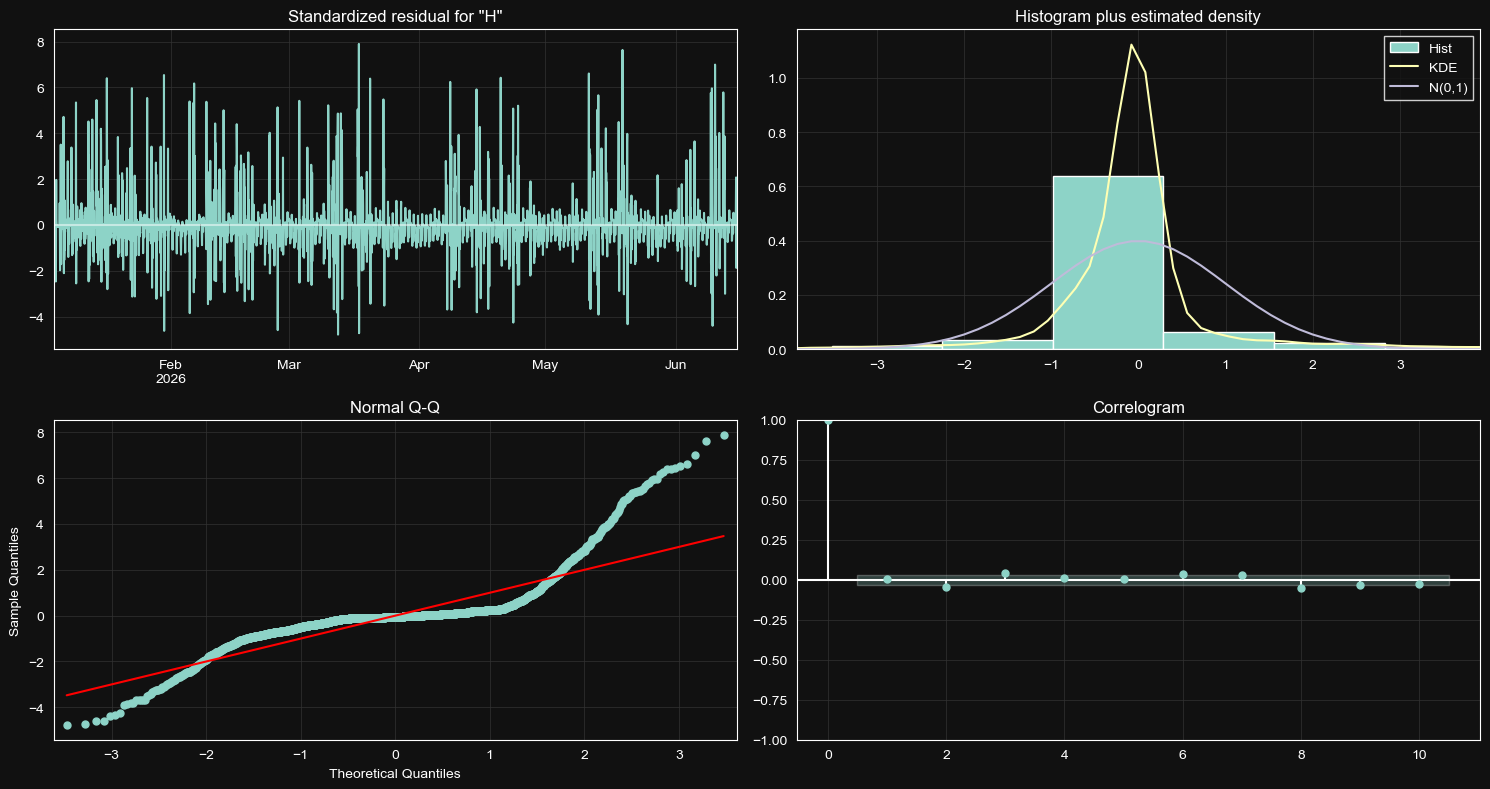

In [37]:
fig = resultados.plot_diagnostics(figsize=(15, 8))
_oscurecer(fig); plt.show()

## Predicción y evaluación del modelo (168 h)

In [38]:
pred = resultados.get_forecast(steps=len(test), exog=exog_fut)
pred_mean = pred.predicted_mean.clip(lower=0)   # las horas-hombre no pueden ser negativas
pred_mean.index = test.index                    # alinear al rango de prueba
pred_mean.head()

2026-06-15 13:00:00    0.792750
2026-06-15 14:00:00    0.748475
2026-06-15 15:00:00    0.950628
2026-06-15 16:00:00    0.867137
2026-06-15 17:00:00    0.293864
Freq: h, Name: predicted_mean, dtype: float64

In [39]:
pred_IC = pred.conf_int().clip(lower=0)
pred_IC.index = test.index
pred_IC.tail()

,lower HorasHombre,upper HorasHombre
2026-06-22 08:00:00,0.0,2.931051
2026-06-22 09:00:00,0.0,3.275565
2026-06-22 10:00:00,0.0,3.322507
2026-06-22 11:00:00,0.0,3.265809
2026-06-22 12:00:00,0.0,3.335774


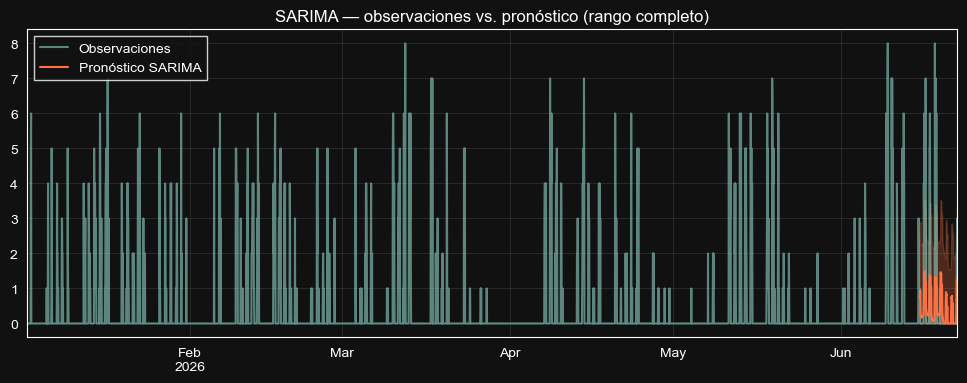

In [40]:
ax = datos["HorasHombre"].plot(label="Observaciones", figsize=(12, 4), alpha=0.6)
pred_mean.plot(ax=ax, label="Pronóstico SARIMA", color="#FF7043")
ax.fill_between(pred_IC.index, pred_IC.iloc[:, 0], pred_IC.iloc[:, 1], color="#FF7043", alpha=0.25)
plt.title("SARIMA — observaciones vs. pronóstico (rango completo)")
plt.legend(); plt.show()

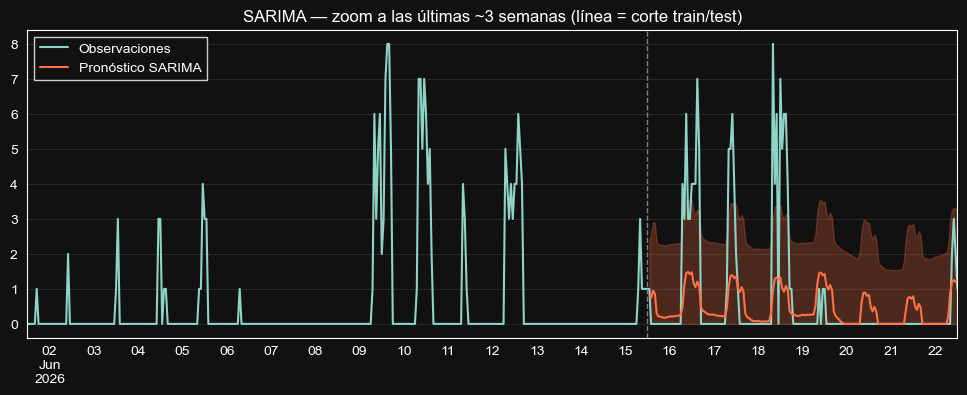

In [41]:
zoom = split_ts - pd.Timedelta(days=14)
ax = datos.loc[zoom:, "HorasHombre"].plot(label="Observaciones", figsize=(12, 4))
pred_mean.plot(ax=ax, label="Pronóstico SARIMA", color="#FF7043")
ax.fill_between(pred_IC.index, pred_IC.iloc[:, 0], pred_IC.iloc[:, 1], color="#FF7043", alpha=0.25)
plt.axvline(split_ts, color="gray", ls="--", lw=1)
plt.title("SARIMA — zoom a las últimas ~3 semanas (línea = corte train/test)")
plt.legend(); plt.show()

In [42]:
def metricas(y_real, y_pred, etiqueta):
    y_real, y_pred = y_real.align(y_pred, join="inner")
    assert y_pred.index.equals(y_real.index) and len(y_pred) == len(test)
    rmse = np.sqrt(mean_squared_error(y_real, y_pred))
    mae  = mean_absolute_error(y_real, y_pred)
    lab  = y_real.index.hour.isin(list(HORAS_LAB))
    rmse_lab = np.sqrt(mean_squared_error(y_real[lab], y_pred[lab]))
    pos  = y_real > 0
    mape = (np.abs((y_real[pos] - y_pred[pos]) / y_real[pos])).mean() * 100
    print(f"[{etiqueta}]  RMSE={rmse:.2f}  MAE={mae:.2f}  "
          f"RMSE(06-20h)={rmse_lab:.2f}  MAPE(y>0)={mape:.1f}%   [horas-hombre/h]")
    return rmse

rmse_sarima = metricas(test, pred_mean, "SARIMA")

[SARIMA]  RMSE=1.52  MAE=0.77  RMSE(06-20h)=1.92  MAPE(y>0)=61.9%   [horas-hombre/h]


# Prophet

Prophet ajusta un modelo **aditivo** con estacionalidades múltiples. Aquí brilla: maneja de forma
**nativa** la estacionalidad **diaria** (doble pico) y la **semanal** (caída de fin de semana), sin
exógenas. `yearly_seasonality=False` (solo ~25 semanas de datos).

In [43]:
train_Prophet = train.reset_index()
train_Prophet.columns = ["ds", "y"]
train_Prophet.tail()

,ds,y
3944,2026-06-15 08:00:00,3.0
3945,2026-06-15 09:00:00,1.0
3946,2026-06-15 10:00:00,1.0
3947,2026-06-15 11:00:00,1.0
3948,2026-06-15 12:00:00,1.0


## Modelo 1 — estacionalidad diaria + semanal

In [44]:
model_prophet = Prophet(daily_seasonality=True, weekly_seasonality=True,
                        yearly_seasonality=False, interval_width=0.95)
model_prophet.fit(train_Prophet)

AttributeError: 'Prophet' object has no attribute 'stan_backend'

In [ ]:
future_data = model_prophet.make_future_dataframe(periods=PERIODOS_FUT, freq=FREQ)
pred_Prophet = model_prophet.predict(future_data)
pred_Prophet[["ds", "yhat", "yhat_lower", "yhat_upper"]].tail()

,ds,yhat,yhat_lower,yhat_upper
3993,2026-06-17 09:00:00,1.332027,-0.624933,3.307494
3994,2026-06-17 10:00:00,1.482439,-0.704191,3.568367
3995,2026-06-17 11:00:00,1.404935,-0.486443,3.462956
3996,2026-06-17 12:00:00,1.229779,-0.860030,3.378424
3997,2026-06-17 13:00:00,1.098534,-1.053388,3.100891


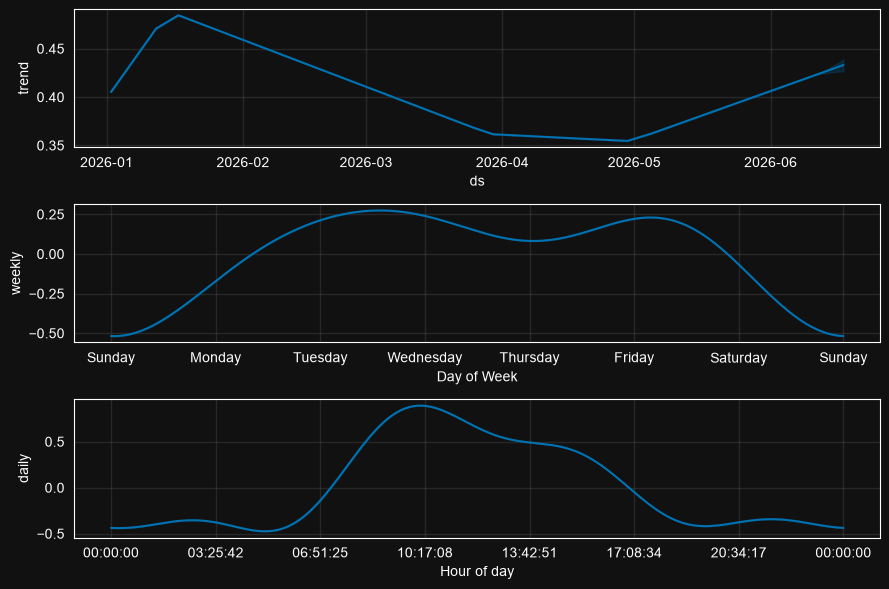

In [ ]:
fig = model_prophet.plot_components(pred_Prophet, uncertainty=True, figsize=(9, 6))
_oscurecer(fig); plt.show()

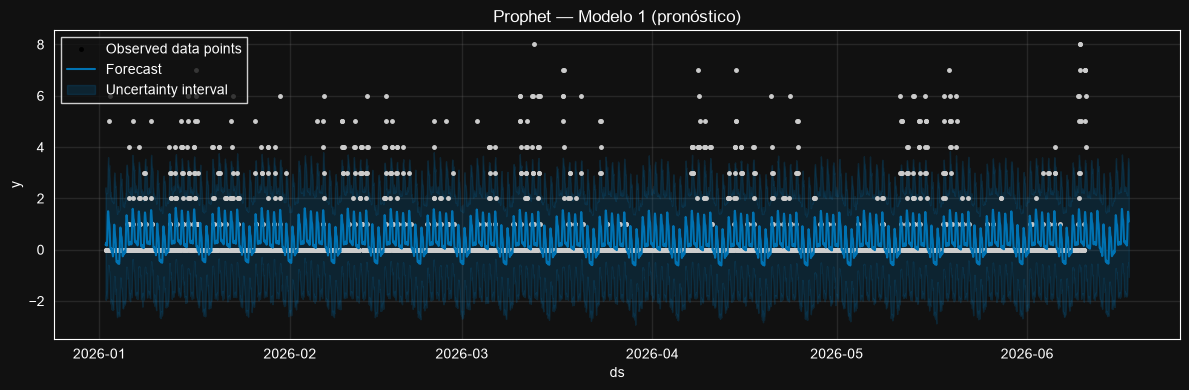

In [ ]:
fig = model_prophet.plot(pred_Prophet, include_legend=True)
fig.set_size_inches(12, 4); plt.title("Prophet — Modelo 1 (pronóstico)")
_oscurecer(fig); plt.show()

In [ ]:
prophet_pred = pred_Prophet.set_index("ds")["yhat"].clip(lower=0)
y_pred_p1 = prophet_pred.reindex(test.index)
rmse_prophet1 = metricas(test, y_pred_p1, "Prophet M1")

[Prophet M1]  RMSE=1.42  MAE=0.77  RMSE(06-20h)=1.78  MAPE(y>0)=60.2%   [horas-hombre/h]


## Modelo 2 — eventos de baja carga (festivos / cierres entre semana)

Donde el tutorial usaba "periodos de recesión", aquí modelamos los **días entre semana sin
actividad** (festivos MX / cierres) como *holidays* de Prophet. **No** incluimos fines de semana: ya
los captura `weekly_seasonality` (serían colineales).

In [ ]:
# Días laborales (Lun–Vie) con CERO horas-hombre = festivos/cierres (data-driven).
carga_dia = datos["HorasHombre"].groupby(datos.index.normalize()).sum()
es_laboral = carga_dia.index.dayofweek < 5
cierres = carga_dia.index[(carga_dia.values == 0) & es_laboral]
eventos = pd.DataFrame({"holiday": "cierre_entre_semana", "ds": cierres})
eventos["lower_window"] = 0
eventos["upper_window"] = 0
print(f"Eventos de baja carga (festivos/cierres entre semana): {len(eventos)}")
eventos

Eventos de baja carga (festivos/cierres entre semana): 18


,holiday,ds,lower_window,upper_window
0,cierre_entre_semana,2026-02-02,0,0
1,cierre_entre_semana,2026-02-03,0,0
2,cierre_entre_semana,2026-02-04,0,0
3,cierre_entre_semana,2026-03-02,0,0
4,cierre_entre_semana,2026-03-16,0,0
5,cierre_entre_semana,2026-03-25,0,0
6,cierre_entre_semana,2026-03-30,0,0
7,cierre_entre_semana,2026-03-31,0,0
8,cierre_entre_semana,2026-04-01,0,0
9,cierre_entre_semana,2026-04-02,0,0


In [ ]:
model_prophet2 = Prophet(daily_seasonality=True, weekly_seasonality=True,
                         yearly_seasonality=False, interval_width=0.95,
                         holidays=eventos if len(eventos) else None)  # robusto si no hay cierres
model_prophet2.fit(train_Prophet)

16:21:55 [INFO] Chain [1] start processing


16:21:55 [INFO] Chain [1] done processing


In [ ]:
future_data2 = model_prophet2.make_future_dataframe(periods=PERIODOS_FUT, freq=FREQ)
pred_Prophet2 = model_prophet2.predict(future_data2)
pred_Prophet2.set_index("ds", inplace=True)

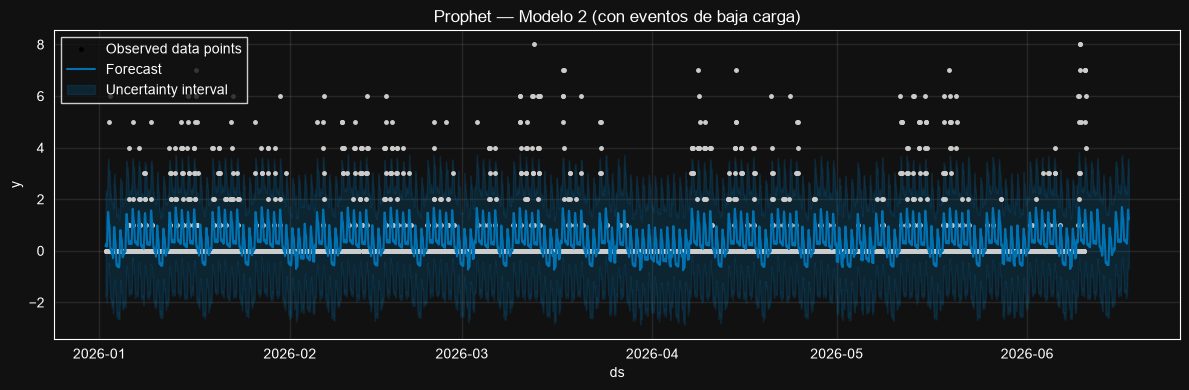

In [ ]:
fig = model_prophet2.plot(pred_Prophet2.reset_index(), include_legend=True)
fig.set_size_inches(12, 4); plt.title("Prophet — Modelo 2 (con eventos de baja carga)")
_oscurecer(fig); plt.show()

In [ ]:
int_conf_Prophet2 = pred_Prophet2[["yhat_lower", "yhat_upper"]].clip(lower=0)
int_conf_Prophet2.tail(PERIODOS_FUT).head()

,yhat_lower,yhat_upper
ds,,
2026-06-10 14:00:00,0.0,3.298731
2026-06-10 15:00:00,0.0,3.111511
2026-06-10 16:00:00,0.0,2.880791
2026-06-10 17:00:00,0.0,2.691325
2026-06-10 18:00:00,0.0,2.426187


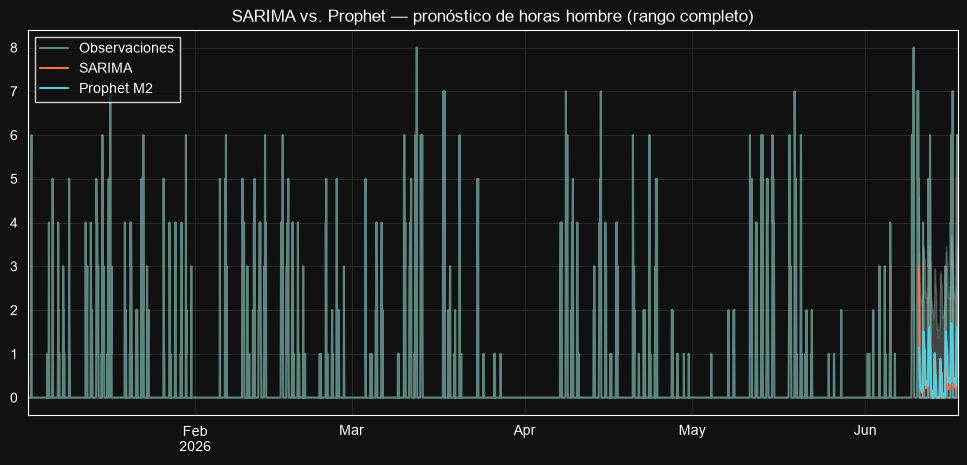

In [ ]:
p2 = pred_Prophet2["yhat"].clip(lower=0).reindex(test.index)
ic2 = int_conf_Prophet2.reindex(test.index)

ax = datos["HorasHombre"].plot(label="Observaciones", figsize=(12, 5), alpha=0.6)
pred_mean.plot(ax=ax, label="SARIMA", color="#FF7043")
ax.fill_between(pred_IC.index, pred_IC.iloc[:, 0], pred_IC.iloc[:, 1], color="#FF7043", alpha=0.2)
p2.plot(ax=ax, label="Prophet M2", color="#4DD0E1")
ax.fill_between(test.index, ic2.iloc[:, 0], ic2.iloc[:, 1], color="#4DD0E1", alpha=0.2)
plt.title("SARIMA vs. Prophet — pronóstico de horas hombre (rango completo)")
plt.legend(); plt.show()

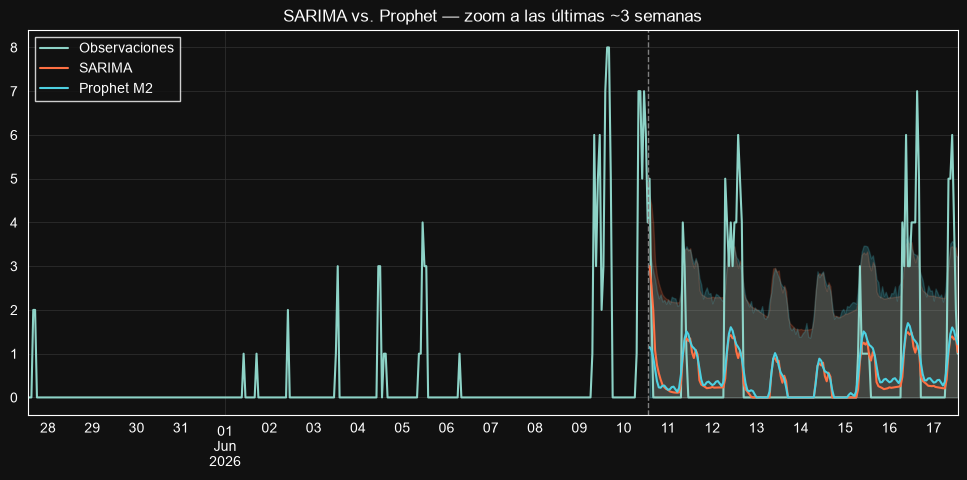

In [ ]:
ax = datos.loc[zoom:, "HorasHombre"].plot(label="Observaciones", figsize=(12, 5))
pred_mean.plot(ax=ax, label="SARIMA", color="#FF7043")
ax.fill_between(pred_IC.index, pred_IC.iloc[:, 0], pred_IC.iloc[:, 1], color="#FF7043", alpha=0.2)
p2.plot(ax=ax, label="Prophet M2", color="#4DD0E1")
ax.fill_between(test.index, ic2.iloc[:, 0], ic2.iloc[:, 1], color="#4DD0E1", alpha=0.2)
plt.axvline(split_ts, color="gray", ls="--", lw=1)
plt.title("SARIMA vs. Prophet — zoom a las últimas ~3 semanas")
plt.legend(); plt.show()

In [ ]:
rmse_prophet2 = metricas(test, p2, "Prophet M2")
print()
print(f"RMSE  SARIMA={rmse_sarima:.2f} | Prophet M1={rmse_prophet1:.2f} | "
      f"Prophet M2={rmse_prophet2:.2f}   [horas-hombre/h]")

[Prophet M2]  RMSE=1.39  MAE=0.81  RMSE(06-20h)=1.75  MAPE(y>0)=60.0%   [horas-hombre/h]

RMSE  SARIMA=1.40 | Prophet M1=1.42 | Prophet M2=1.39   [horas-hombre/h]


## Conclusión y advertencias

- Se compara el **error puntual** (RMSE/MAE), no el ancho de banda: SARIMA usa IC analítico de
  espacio de estados y Prophet, muestreo — no son equivalentes.
- El **horizonte es de 168 h**: solo las primeras ~24–72 h tienen banda estrecha; los días 4–7 son
  indicativos. La banda inferior se recortó a 0 (conservadora).
- **Caveats:** la variable es un **proxy de presencia** (no horas de nómina); el *snapshot* es de
  ~6 meses (ene–jun 2026), por lo que solo son creíbles horizontes de **días a semanas** y no
  hay efecto anual estimable. La estacionalidad **semanal** la captura Prophet de forma nativa y
  SARIMA vía **exógenas de Fourier**.
- Para producción conviene **volver a consultar el API SGA** y reentrenar; el orden SARIMA y
  `K_FOURIER` son ajustables según evolucione la operación.

# Apéndice — serie de horario laboral 06–20h (s=15) · solo comparación

⚠️ **Caveat de pseudo-continuidad:** al quitar las horas 21–05h, el *lag* estacional s=15 salta
huecos reales (noche y fin de semana), así que las distancias del modelo dejan de coincidir con el
tiempo de reloj. **No** es el pronóstico reportado; se incluye solo como comparación rápida.

In [ ]:
ent_lab = ent[ent["hora"].between(6, 20)]
hh_lab = ent_lab.groupby("ts")["usuario"].nunique()
rejilla_lab = pd.DatetimeIndex([
    d + pd.Timedelta(hours=h)
    for d in pd.date_range(hh_lab.index.min().floor("D"), hh_lab.index.max().floor("D"), freq="D")
    for h in HORAS_LAB
])
serie_lab = hh_lab.reindex(rejilla_lab).fillna(0).astype(float)
print(f"Serie laboral 06-20h: {len(serie_lab):,} puntos (s=15), {(serie_lab == 0).mean():.0%} ceros")

Serie laboral 06-20h: 2,505 puntos (s=15), 77% ceros


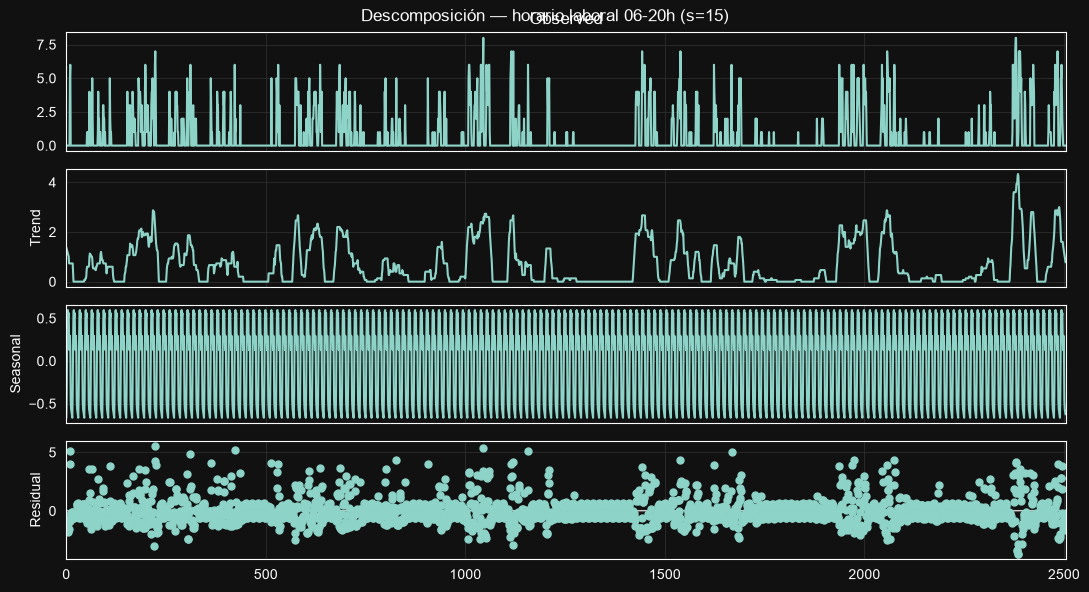

In [ ]:
dec_lab = seasonal_decompose(serie_lab.to_numpy(), model="additive", period=15, extrapolate_trend="freq")
fig = dec_lab.plot(); fig.set_size_inches(11, 6)
_oscurecer(fig); plt.suptitle("Descomposición — horario laboral 06-20h (s=15)"); plt.show()